In [7]:
#doc du lieu
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import os

df = pd.read_excel("default of credit card clients.xls",
    header=1)
print("Kich co du lieu: ", df.shape)
display(df.head(5))

Kich co du lieu:  (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [8]:
#khao sat, chuan hoa du lieu
print("Thong tin du lieu: ")
df.info()

print("\nSo luong gia tri thieu:")
print(df.isnull().sum())

print("So dong trung: ", df.duplicated().sum())

print("\nThong ke mo ta: ")
print(df.describe())

print("Ten cot trc khi chuan hoa: ", df.columns)
print(df.columns.tolist())

df.columns = [str(c) for c in df.columns]
print("Ten cot sau khi xoa khoang trang: ", df.columns.tolist())

rename_map = {
    'default payment next month': 'default_next_month',
    "Y": "default_next_month",
    "X1": "LIMIT_BAL",
    "X2": "SEX",
    "X3": "EDUCATION",
    "X4": "MARRIAGE",
    "X5": "AGE",

    "X6": "PAY_0",
    "X7": "PAY_2",
    "X8": "PAY_3",
    "X9": "PAY_4",
    "X10": "PAY_5",
    "X11": "PAY_6",

    "X12": "BILL_AMT1",
    "X13": "BILL_AMT2",
    "X14": "BILL_AMT3",
    "X15": "BILL_AMT4",
    "X16": "BILL_AMT5",
    "X17": "BILL_AMT6",

    "X18": "PAY_AMT1",
    "X19": "PAY_AMT2",
    "X20": "PAY_AMT3",
    "X21": "PAY_AMT4",
    "X22": "PAY_AMT5",
    "X23": "PAY_AMT6"
}

df.rename(columns=rename_map, inplace=True)
print("Ten cot sau khi chuan hoa: ", df.columns.tolist())

if "default_next_month" in df.columns:
    candidates=[c for c in df.columns if "default" in c.lower() or c.lower()=="Y"]
    if candidates:
        df=df.rename(columns={candidates[-1]:"default_next_month"})

if "default_next_month" not in df.columns:
    raise ValueError("Không tìm thấy cột nhãn. Hãy kiểm tra tên cột của file dữ liệu.")

print("Kích thước dữ liệu:", df.shape)
display(df.head())


Thong tin du lieu: 
<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null  int64
 1

C:\Users\ANH\AppData\Local\Temp\ipykernel_28024\3263423910.py:50: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns=rename_map, inplace=True)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default_next_month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [9]:
#cau truc & chat luong du lieu
print("So dong: ", df.shape[0])
print("So cot: ", df.shape[1])
display(pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2), 
    "n_inunique": df.nunique()
}).sort_values(by="missing_pct", ascending=False))
print("So dong trung hoan toan: ", df.duplicated().sum())
if "ID" in df.columns:
    print("ID duy nhat: ", df["ID"].nunique(), "/", len(df))

So dong:  30000
So cot:  25


,dtype,missing_count,missing_pct,n_inunique
ID,int64,0,0.0,30000
LIMIT_BAL,int64,0,0.0,81
SEX,int64,0,0.0,2
EDUCATION,int64,0,0.0,7
MARRIAGE,int64,0,0.0,4
AGE,int64,0,0.0,56
PAY_0,int64,0,0.0,11
PAY_2,int64,0,0.0,11
PAY_3,int64,0,0.0,11
PAY_4,int64,0,0.0,11


So dong trung hoan toan:  0
ID duy nhat:  30000 / 30000


In [10]:
#thong ke mo ta
display(df.describe(include="all").T)

# thong ke rieng cho cac nhom bien chinh
pay_cols = [c for c in ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"] if c in df.columns]
bill_cols = [c for c in df.columns if c.startswith("BILL_AMT")]
payment_cols = [c for c in df.columns if c.startswith("PAY_AMT")]
amount_cols = [c for c in ["LIMIT_BAL", "AGE"] + bill_cols + payment_cols if c in df.columns]

if amount_cols:
    display(df[amount_cols].describe(percentiles=[.01, .25, .5, .75, .95, .99]).T)

,count,mean,std,min,25%,50%,75%,max
ID,30000.0,15000.500000,8660.398374,1.0,7500.75,15000.5,22500.25,30000.0
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0


,count,mean,std,min,1%,25%,50%,75%,95%,99%,max
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,10000.00,50000.00,140000.0,240000.00,430000.00,500000.00,1000000.0
AGE,30000.0,35.485500,9.217904,21.0,22.00,28.00,34.0,41.00,53.00,60.00,79.0
BILL_AMT1,30000.0,51223.330900,73635.860576,-165580.0,-81.00,3558.75,22381.5,67091.00,201203.05,350110.68,964511.0
BILL_AMT2,30000.0,49179.075167,71173.768783,-69777.0,-200.00,2984.75,21200.0,64006.25,194792.20,337495.28,983931.0
BILL_AMT3,30000.0,47013.154800,69349.387427,-157264.0,-200.00,2666.25,20088.5,60164.75,187821.05,325030.39,1664089.0
BILL_AMT4,30000.0,43262.948967,64332.856134,-170000.0,-212.02,2326.75,19052.0,54506.00,174333.35,304997.27,891586.0
BILL_AMT5,30000.0,40311.400967,60797.155770,-81334.0,-232.01,1763.00,18104.5,50190.50,165794.30,285868.33,927171.0
BILL_AMT6,30000.0,38871.760400,59554.107537,-339603.0,-331.03,1256.00,17071.0,49198.25,161912.00,279505.06,961664.0
PAY_AMT1,30000.0,5663.580500,16563.280354,0.0,0.00,1000.00,2100.0,5006.00,18428.20,66522.18,873552.0
PAY_AMT2,30000.0,5921.163500,23040.870402,0.0,0.00,833.00,2009.0,5000.00,19004.35,76651.02,1684259.0


In [11]:
#bien phan loai/thu tu bang tan suat
for c in ["SEX", "EDUCATION", "MARRIAGE"]:
    print(f"\n{c}"); display(df[c].value_counts().sort_index().to_frame("so_khach_hang").assign(ty_le_pct=lambda x: (x.so_khach_hang / len(df) * 100).round(2)).T)
print("\nPAY_0 (trạng thái thanh toán tháng gần nhất)")
display(df["PAY_0"].value_counts().sort_index().to_frame("so_khach_hang").T)


SEX


SEX,1,2
so_khach_hang,11888.00,18112.00
ty_le_pct,39.63,60.37



EDUCATION


EDUCATION,0,1,2,3,4,5,6
so_khach_hang,14.00,10585.00,14030.00,4917.00,123.00,280.00,51.00
ty_le_pct,0.05,35.28,46.77,16.39,0.41,0.93,0.17



MARRIAGE


MARRIAGE,0,1,2,3
so_khach_hang,54.00,13659.00,15964.00,323.00
ty_le_pct,0.18,45.53,53.21,1.08



PAY_0 (trạng thái thanh toán tháng gần nhất)


PAY_0,-2,-1,0,1,2,3,4,5,6,7,8
so_khach_hang,2759,5686,14737,3688,2667,322,76,26,11,9,19


,count,percent
default_next_month,,
0,23364,77.88
1,6636,22.12


Tỷ lệ vỡ nợ (nhãn 1): 22.12%


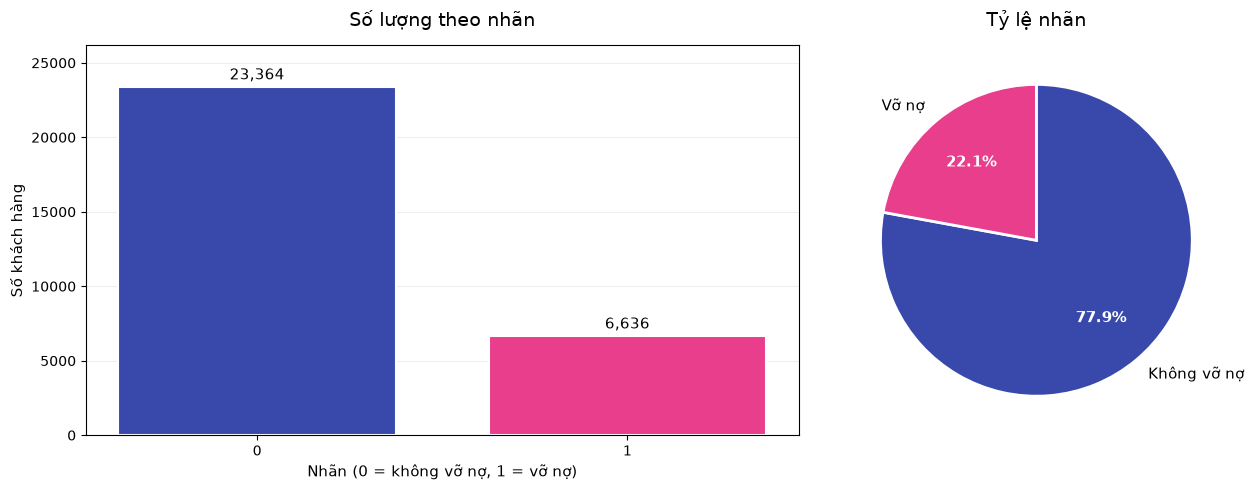

In [12]:


# Tên cột mục tiêu
target = "default_next_month"

# Thống kê nhãn 0 và 1
target_counts = (
    df[target]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

target_pct = target_counts / target_counts.sum() * 100

display(pd.DataFrame({
    "count": target_counts,
    "percent": target_pct.round(2)
}))

print(
    f"Tỷ lệ vỡ nợ (nhãn 1): "
    f"{target_pct.loc[1]:.2f}%"
)

# Bảng màu theo hình bạn gửi
blue = "#3949AB"       # Xanh dương
purple = "#29108F"     # Tím đậm
pink = "#E83E8C"       # Hồng
orange = "#F5A14B"     # Cam
lavender = "#8E63B6"   # Tím nhạt

colors = [blue, pink]
background = "#FFFFFF"

# Tạo thư mục lưu biểu đồ
os.makedirs("figures", exist_ok=True)

# Tạo 2 biểu đồ cạnh nhau
fig, ax = plt.subplots(
    1, 2,
    figsize=(13, 5),
    gridspec_kw={"width_ratios": [1.6, 1]}
)

fig.patch.set_facecolor(background)

# =========================
# 1. Biểu đồ cột
# =========================
bars = ax[0].bar(
    [str(i) for i in target_counts.index],
    target_counts.values,
    color=colors,
    width=0.75,
    edgecolor="white",
    linewidth=1.5
)

ax[0].set_title(
    "Số lượng theo nhãn",
    fontsize=14,
    pad=14
)
ax[0].set_xlabel(
    "Nhãn (0 = không vỡ nợ, 1 = vỡ nợ)",
    fontsize=11
)
ax[0].set_ylabel("Số khách hàng", fontsize=11)

ax[0].set_facecolor(background)
ax[0].grid(axis="y", alpha=0.2)
ax[0].set_axisbelow(True)

# Hiển thị số lượng trên đầu cột
ax[0].bar_label(
    bars,
    labels=[f"{int(v):,}" for v in target_counts.values],
    padding=3,
    fontsize=11
)

ax[0].set_ylim(0, max(target_counts.max() * 1.12, 1))

# =========================
# 2. Biểu đồ tròn
# =========================
wedges, texts, autotexts = ax[1].pie(
    target_counts.values,
    labels=["Không vỡ nợ", "Vỡ nợ"],
    autopct="%1.1f%%",
    colors=colors,
    startangle=90,
    counterclock=False,
    pctdistance=0.65,
    labeldistance=1.12,
    wedgeprops={
        "edgecolor": "white",
        "linewidth": 2
    },
    textprops={"fontsize": 11}
)

for text in autotexts:
    text.set_fontsize(11)
    text.set_color("white")
    text.set_fontweight("bold")

ax[1].set_title(
    "Tỷ lệ nhãn",
    fontsize=14,
    pad=14
)

# Lưu và hiển thị
plt.tight_layout()

plt.savefig(
    "figures/01_label_distribution.png",
    dpi=200,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()


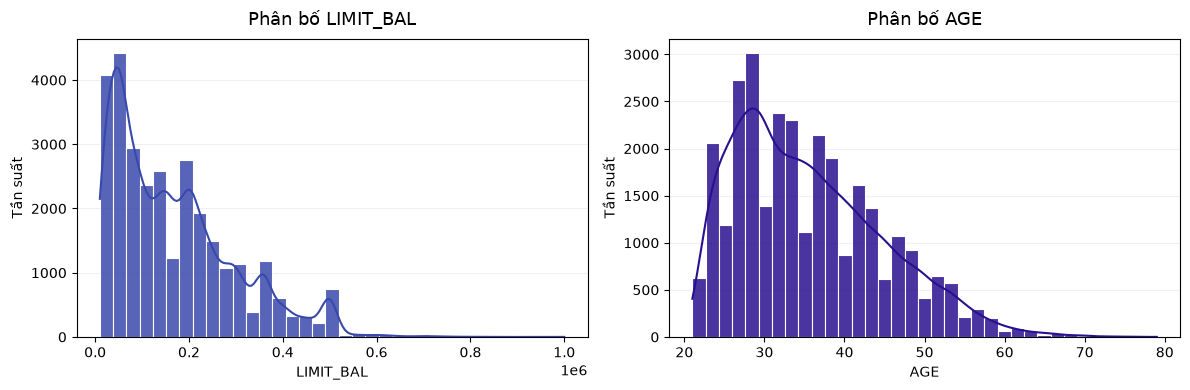

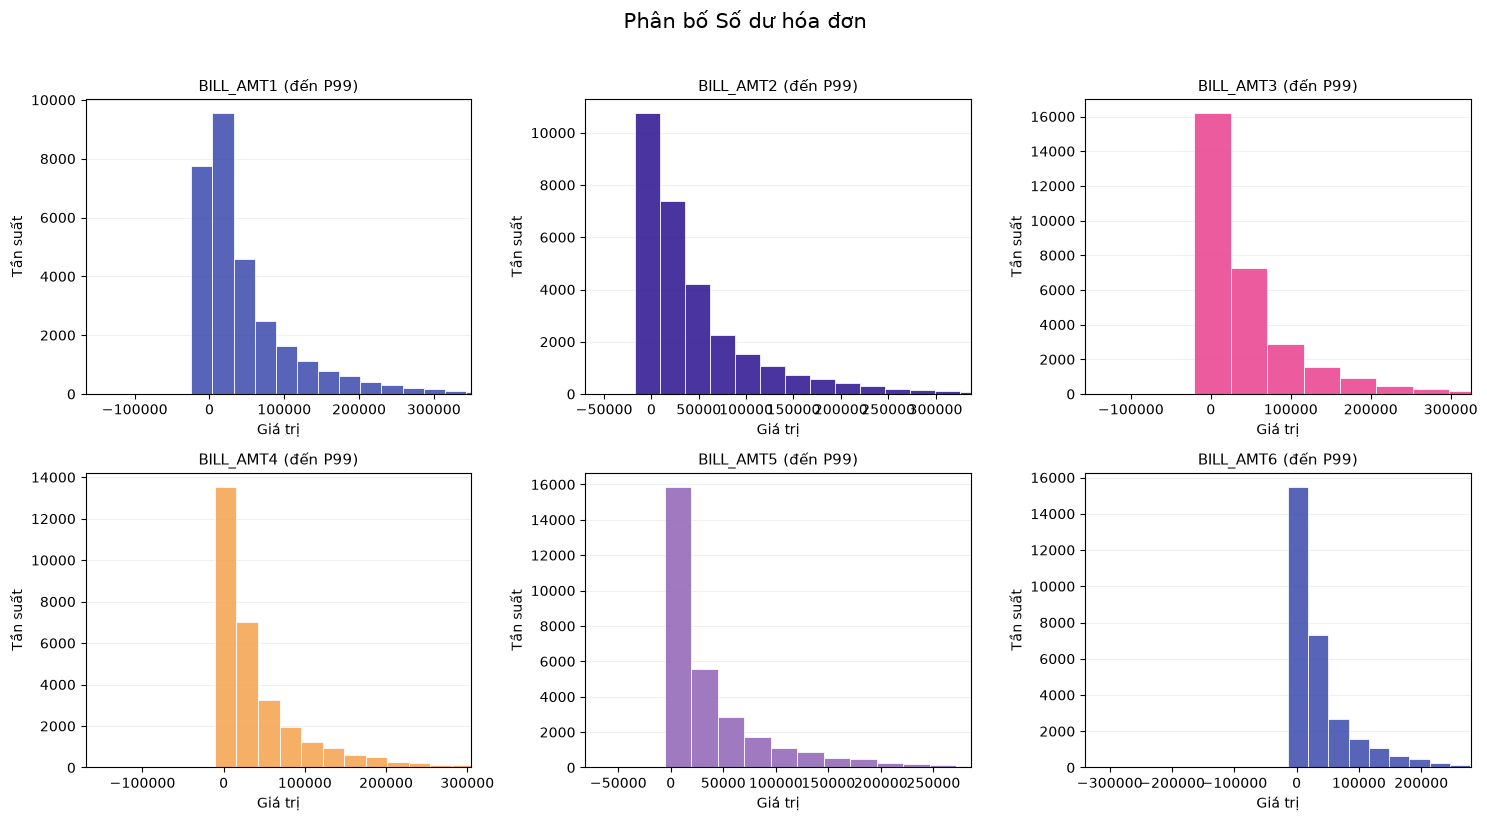

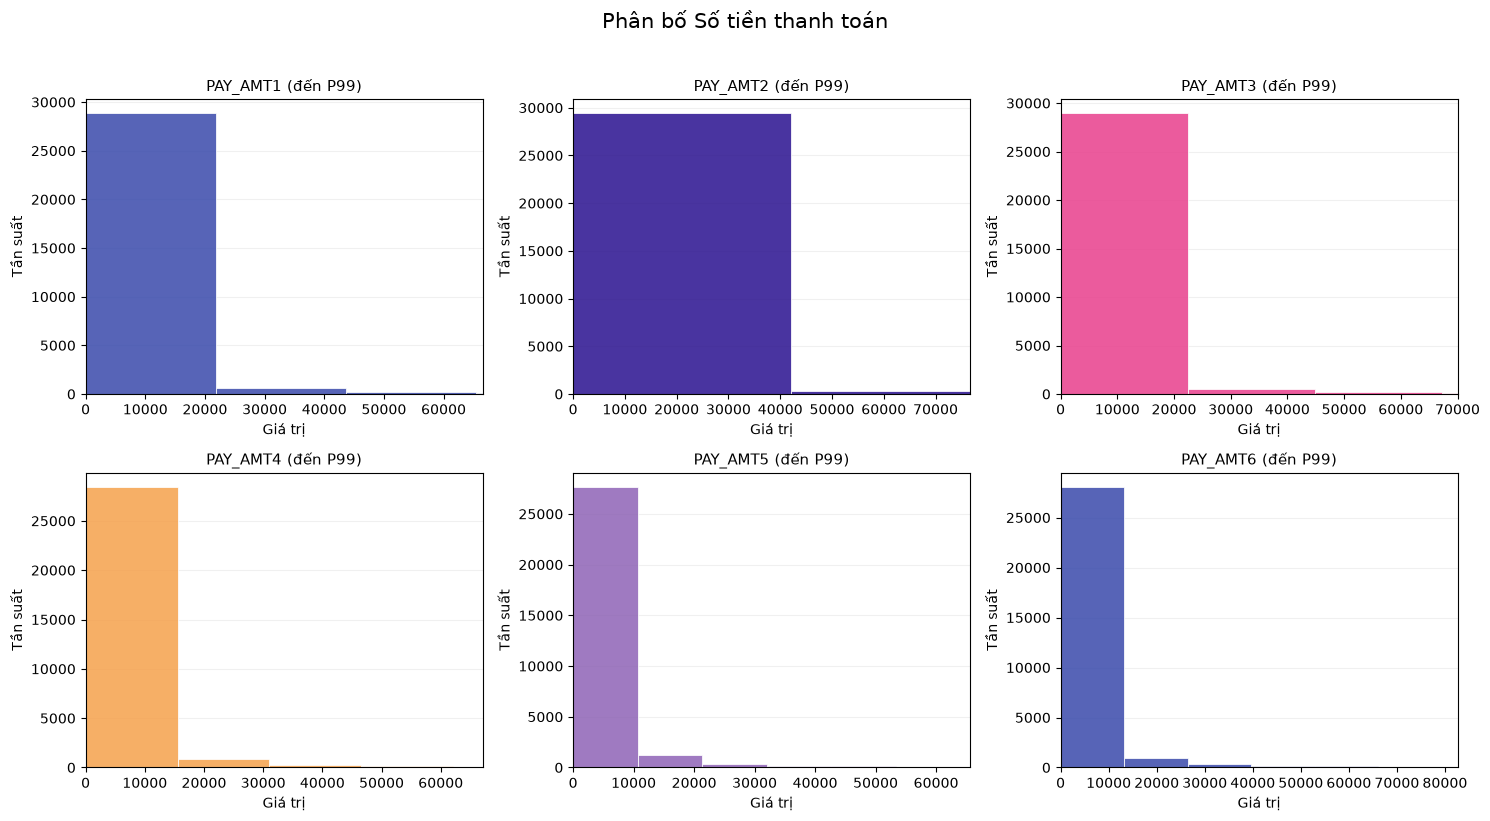

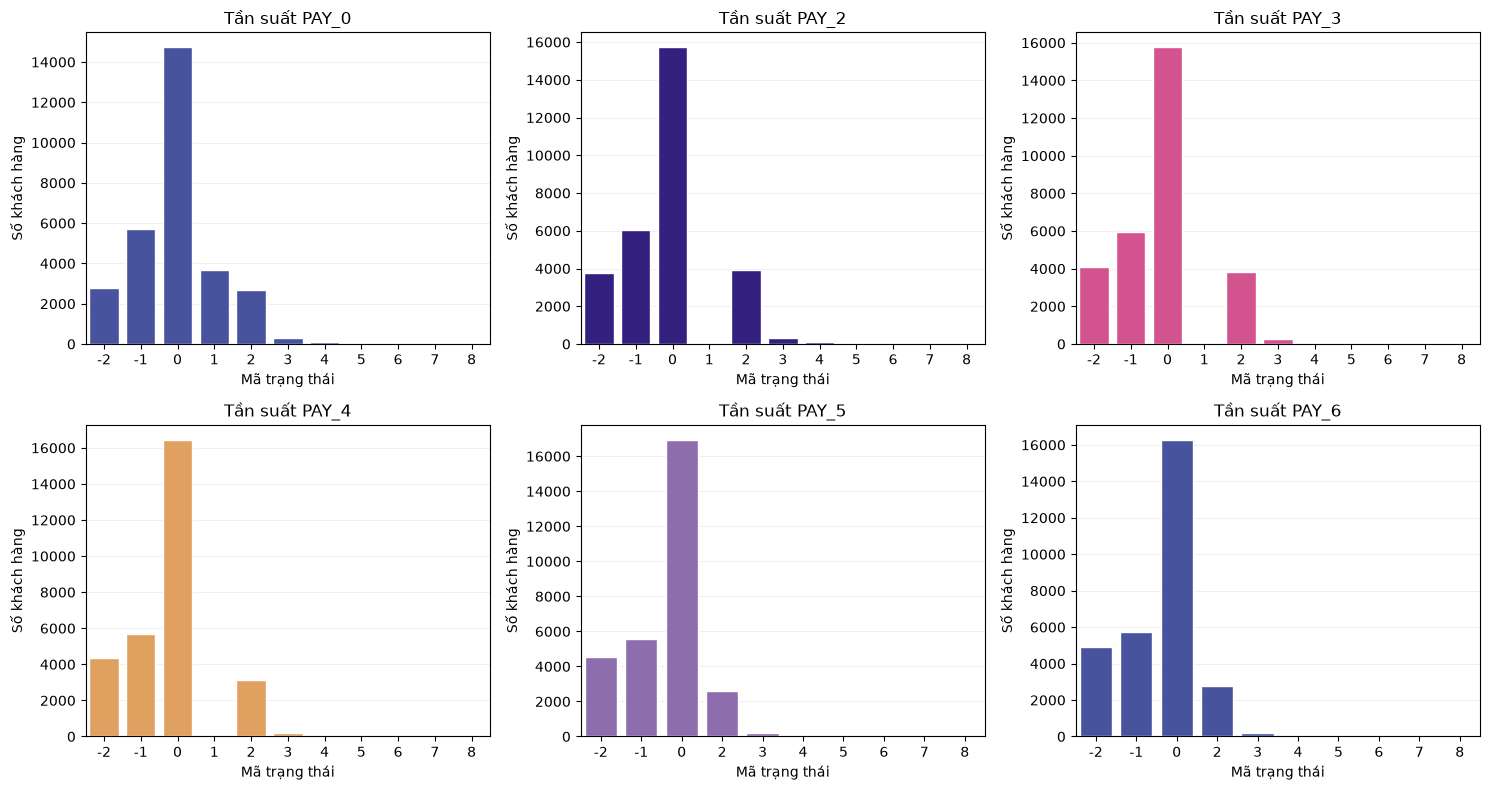

In [13]:
bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
payment_cols = [f"PAY_AMT{i}" for i in range(1, 7)]
pay_cols = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]

# Hạn mức tín dụng và tuổi
import matplotlib.pyplot as plt
import seaborn as sns

# Bảng màu pastel đậm
blue = "#3949AB"       # Xanh dương
purple = "#29108F"     # Tím đậm
pink = "#E83E8C"       # Hồng
orange = "#F5A14B"     # Cam
lavender = "#8E63B6"   # Tím nhạt

palette = [blue, purple, pink, orange, lavender]

# 1. Phân bố hạn mức tín dụng và tuổi
numeric_main = [
    c for c in ["LIMIT_BAL", "AGE"]
    if c in df.columns
]

if numeric_main:
    fig, axes = plt.subplots(
        1, len(numeric_main),
        figsize=(6 * len(numeric_main), 4)
    )

    if len(numeric_main) == 1:
        axes = [axes]

    for i, (col, ax) in enumerate(zip(numeric_main, axes)):
        sns.histplot(
            data=df,
            x=col,
            bins=35,
            kde=True,
            color=palette[i % len(palette)],
            edgecolor="white",
            alpha=0.85,
            ax=ax
        )

        ax.set_title(f"Phân bố {col}", fontsize=13, pad=10)
        ax.set_xlabel(col)
        ax.set_ylabel("Tần suất")
        ax.grid(axis="y", alpha=0.18)
        ax.set_axisbelow(True)

    plt.tight_layout()
    plt.show()


# 2. Phân bố số dư hóa đơn và số tiền thanh toán
for group_name, cols in [
    ("Số dư hóa đơn", bill_cols),
    ("Số tiền thanh toán", payment_cols)
]:
    cols = [c for c in cols if c in df.columns]

    if cols:
        fig, axes = plt.subplots(2, 3, figsize=(15, 8))
        axes = axes.flatten()

        for i, (col, ax) in enumerate(zip(cols, axes)):
            series = df[col].dropna()

            if series.empty:
                ax.set_visible(False)
                continue

            color = palette[i % len(palette)]

            sns.histplot(
                series,
                bins=40,
                color=color,
                edgecolor="white",
                alpha=0.85,
                ax=ax
            )

            q99 = series.quantile(0.99)
            lower = min(0, series.min())

            ax.set_xlim(
                left=lower,
                right=q99 if q99 > lower else None
            )

            ax.set_title(f"{col} (đến P99)", fontsize=11)
            ax.set_xlabel("Giá trị")
            ax.set_ylabel("Tần suất")
            ax.grid(axis="y", alpha=0.18)
            ax.set_axisbelow(True)

        for ax in axes[len(cols):]:
            ax.set_visible(False)

        fig.suptitle(
            f"Phân bố {group_name}",
            fontsize=15,
            y=1.02
        )

        plt.tight_layout()
        plt.show()


# 3. Tần suất các trạng thái thanh toán
if pay_cols:
    valid_pay_cols = [c for c in pay_cols if c in df.columns]

    if valid_pay_cols:
        fig, axes = plt.subplots(2, 3, figsize=(15, 8))
        axes = axes.flatten()

        for i, (col, ax) in enumerate(
            zip(valid_pay_cols, axes)
        ):
            order = sorted(df[col].dropna().unique())
            color = palette[i % len(palette)]

            sns.countplot(
                data=df,
                x=col,
                order=order,
                color=color,
                edgecolor="white",
                ax=ax
            )

            ax.set_title(f"Tần suất {col}", fontsize=12)
            ax.set_xlabel("Mã trạng thái")
            ax.set_ylabel("Số khách hàng")
            ax.grid(axis="y", alpha=0.18)
            ax.set_axisbelow(True)

        for ax in axes[len(valid_pay_cols):]:
            ax.set_visible(False)

        plt.tight_layout()
        plt.show()
